# Lab 11: Attention


**Completed lab solution.** Original instructions: [NLP_Lab11](https://github.com/MohammedMosuily/NLP_Lab11).

    Run the cells from top to bottom. Results below were generated by executing this notebook. The `dataset` folder contains the original data needed by this lab. Missing Python packages are installed by the setup cell; pretrained model downloads need internet on their first run. Random seeds are fixed where supported.

In [1]:
# Install only missing dependencies into the active Jupyter Python environment.
import importlib.util, subprocess, sys, os, random
from pathlib import Path
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn', 'nltk': 'nltk', 'torch': 'torch'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['USE_TF'] = '0'  # Transformers examples use PyTorch.
os.environ['USE_FLAX'] = '0'
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML
random.seed(42)
np.random.seed(42)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 10)
DATA = Path('dataset')
assert DATA.exists() or 11 in (7, 8, 9), 'Open this notebook from its Lab folder.'

### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
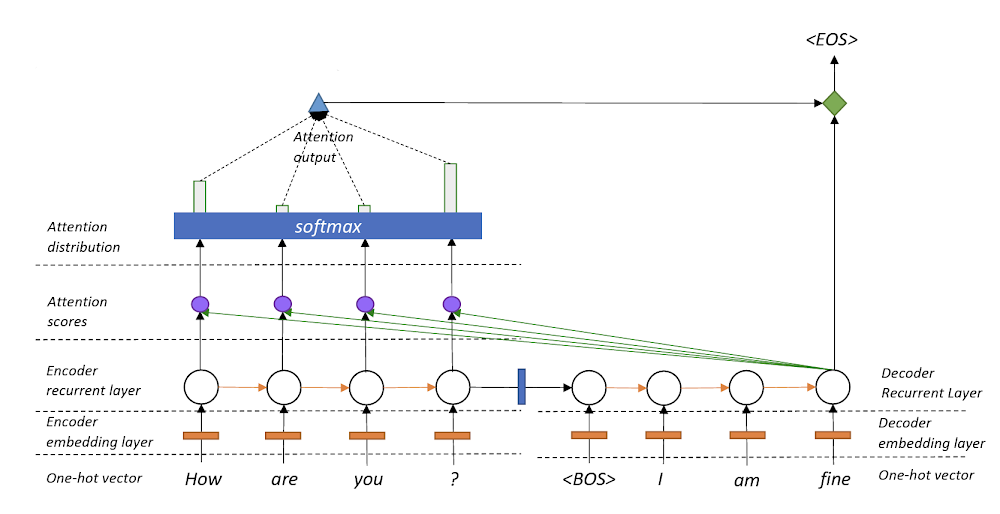

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.manual_seed(42)
torch.set_num_threads(2)

## Step 2 — Upload the dataset

In [3]:
df=pd.read_csv(DATA / 'Lab_11_QnA_Dataset.csv')
print('Number of questions:',len(df))
print('Number of answer groups:',df.answer_id.nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
import re
def question_tokens(question):
    return re.findall(r'[a-z]+',question.lower())
tokenized=[question_tokens(q) for q in df.question]
word_index={word:i+1 for i,word in enumerate(sorted({w for s in tokenized for w in s}))}
max_len=max(map(len,tokenized))
X=torch.zeros((len(df),max_len),dtype=torch.long)
for i,words in enumerate(tokenized):
    X[i,:len(words)]=torch.tensor([word_index[w] for w in words])
y=torch.tensor(df.answer_id.values,dtype=torch.long)
print('Input tensor:',tuple(X.shape),'| Vocabulary:',len(word_index))

Input tensor: (168, 11) | Vocabulary: 225


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb=nn.Embedding(len(word_index)+1,16,padding_idx=0)
        # X is [batch, sequence], so explicitly preserve that order.
        self.rnn=nn.RNN(16,32,batch_first=True)
        self.att=nn.Linear(32,1)
        self.fc=nn.Linear(32,df.answer_id.nunique())
    def forward(self,x):
        hidden,_=self.rnn(self.emb(x))
        scores=self.att(hidden).squeeze(-1)
        scores=scores.masked_fill(x==0,float('-inf'))
        weights=torch.softmax(scores,dim=1)
        context=(hidden*weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context),weights
model=RNN()
print(model)

RNN(
  (emb): Embedding(226, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)
losses=[]
for epoch in range(50):
    model.train()
    optimizer.zero_grad()
    logits,_=model(X)
    loss=nn.functional.cross_entropy(logits,y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch+1)%10==0:print(f'Epoch {epoch+1}/50 | Loss: {loss.item():.4f}')
model.eval()
with torch.no_grad():
    logits,all_weights=model(X)
    print('Training accuracy:',float((logits.argmax(1)==y).float().mean()))
    assert torch.allclose(all_weights.sum(1),torch.ones(len(df)),atol=1e-6)
    assert torch.count_nonzero(all_weights[X==0])==0
print('Training finished; attention weights sum to 1 and padding has weight 0.')

Epoch 10/50 | Loss: 1.8386
Epoch 20/50 | Loss: 1.0374
Epoch 30/50 | Loss: 0.4215
Epoch 40/50 | Loss: 0.1377
Epoch 50/50 | Loss: 0.0464
Training accuracy: 0.9940476417541504
Training finished; attention weights sum to 1 and padding has weight 0.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

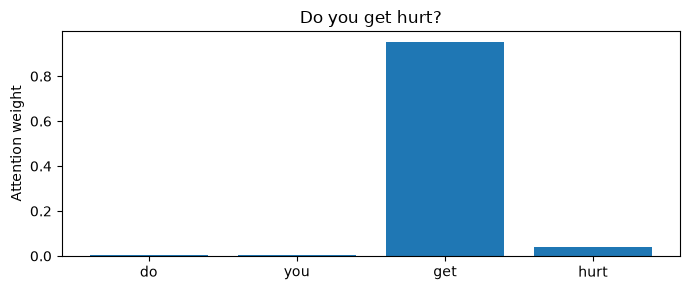

In [7]:
question=df.question.iloc[0]
words=question_tokens(question)
with torch.no_grad():prediction,weights=model(X[:1])
plt.figure(figsize=(7,3))
plt.bar(words,weights[0,:len(words)].numpy())
plt.ylabel('Attention weight');plt.title(question)
plt.tight_layout();plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

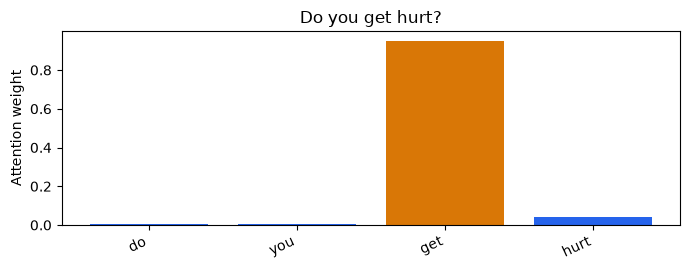

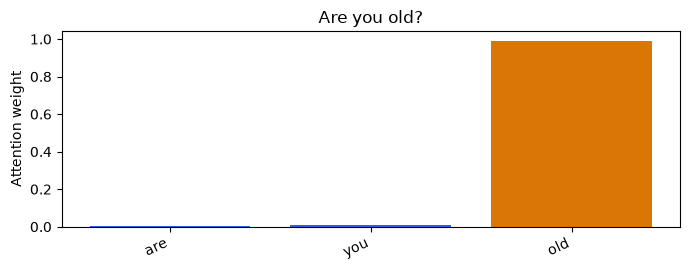

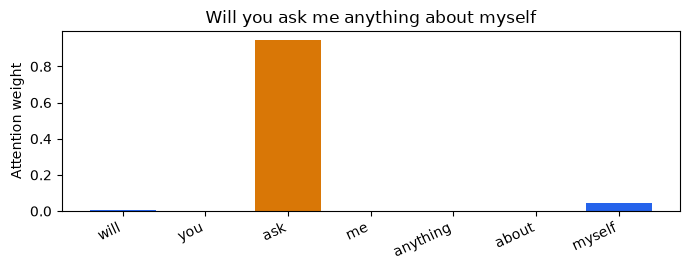

,Question,Highest-attention word,Weight,True answer ID,Predicted answer ID
0,Do you get hurt?,get,0.9521,0,0
1,Are you old?,old,0.9917,1,1
2,Will you ask me anything about myself,ask,0.9470,2,2


In 'Do you get hurt?', the largest weight is on 'get'.
In 'Are you old?', the largest weight is on 'old'.
In 'Will you ask me anything about myself', the largest weight is on 'ask'.


In [8]:
def show_attention(indices):
    rows=[]
    for index in indices:
        words=question_tokens(df.question.iloc[index])
        with torch.no_grad():logits,weights=model(X[index:index+1])
        values=weights[0,:len(words)].numpy()
        best=int(values.argmax())
        prediction=int(logits.argmax(1).item())
        plt.figure(figsize=(7,2.8))
        plt.bar(words,values,color=['#d97706' if i==best else '#2563eb' for i in range(len(words))])
        plt.title(df.question.iloc[index]);plt.ylabel('Attention weight')
        plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
        rows.append({'Question':df.question.iloc[index],'Highest-attention word':words[best],
                     'Weight':round(float(values[best]),4),'True answer ID':int(y[index]),
                     'Predicted answer ID':prediction})
    result=pd.DataFrame(rows)
    display(result)
    return result
task1_results=show_attention([0,14,28])
for row in task1_results.to_dict('records'):
    print(f"In {row['Question']!r}, the largest weight is on {row['Highest-attention word']!r}.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

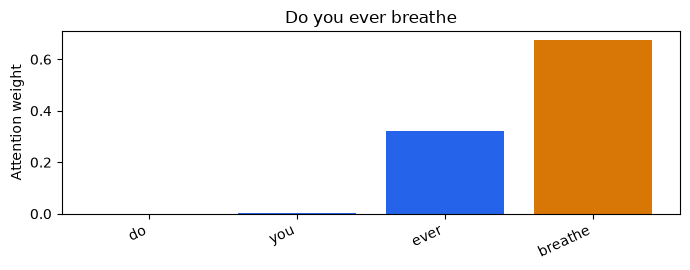

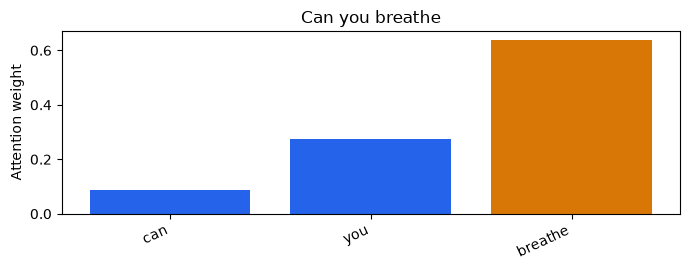

,Question,Highest-attention word,Weight,True answer ID,Predicted answer ID
0,Do you ever breathe,breathe,0.6749,0,0
1,Can you breathe,breathe,0.6381,0,0


Same highest-attention word: True
Focus words: ['breathe', 'breathe']


In [9]:
# Both questions ask whether the chatbot can breathe and share answer group 0.
similar_indices=[2,11]
task2_results=show_attention(similar_indices)
focus=task2_results['Highest-attention word'].tolist()
print('Same highest-attention word:',focus[0]==focus[1])
print('Focus words:',focus)

### Task 1 observations
The largest weights are on **get** (0.9521), **old** (0.9917), and **ask** (0.9470). The latter two clearly relate to age and asking questions; **get** is less informative in isolation, but its contextual state can still contribute to classifying a body-related question. Content words such as body actions or age terms may relate directly to the answer group; if a function word receives the largest weight, that alone is not evidence of an error or a meaningful explanation. Each RNN hidden state already contains preceding context, so a weight on one position can select information from several words. Attention is a learned weighting of representations, not a guaranteed word-importance or causal explanation.

### Task 2 comparison
The two questions, "Do you ever breathe" and "Can you breathe", express the same intent with different wording. Both questions assign the largest weight to **breathe** (0.6749 and 0.6381), so the model focuses on the shared action despite the changed auxiliary wording. Both predict answer group 0 correctly. Similar meanings can yield different weights because the surrounding tokens change the contextual states. The lab trains on all 168 questions to inspect attention, so its reported accuracy is training accuracy and says nothing about unseen-question performance.

### Corrections to the starter
`batch_first=True` prevents the model from treating different questions as successive time steps. Gradients are reset each epoch. Padding is masked before attention softmax and has exactly zero weight. A local regex tokenizer replaces the unnecessary TensorFlow dependency while preserving lowercasing, integer word IDs and post-padding.